# Exploração dos resultados

Gráficos do relatório, gerados a partir dos CSVs em `results/`. Cada figura também é salva em `results/figuras/`.

1. **Acurácia no dataset de treino por cliente**: FedMD adaptado, treino local, FedMD original e centralizado (`results/test_models`).
2. **Evolução de cada etapa do desenvolvimento incremental**: as etapas 1 a 9 da tabela do relatório. No eixo x estão os momentos de avaliação: `pub` (após o `public_init`), `priv` (após o `private_init`) e as rodadas federadas 1…R, cada uma avaliada ao fim da rodada (digest + revisit).
3. **Treino local (public + private init) em cada cenário** da configuração final.

Linha pontilhada: limite teórico (modelo centralizado, 0,898).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

R = 'results'
FIG = os.path.join(R, 'figuras')
os.makedirs(FIG, exist_ok=True)

# Paleta categórica de referência (skill dataviz), slots 1-4 em ordem fixa: cada entidade mantém sempre a mesma cor.
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
TEXT, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
TETO = 0.898  # modelo centralizado, média das 4 arquiteturas (results/limite_teorico)

ALPHAS = ['iid', '1.0', '0.1']
ALPHA_LABEL = {'iid': 'IID', '1.0': 'α = 1.0', '0.1': 'α = 0.1'}
ALPHA_COLOR = dict(zip(ALPHAS, C))

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'axes.titlecolor': TEXT, 'axes.titlesize': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.8, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'legend.frameon': False, 'axes.axisbelow': True, 'font.size': 10, 'lines.linewidth': 2,
})


def load(path):
    """CSV de métricas com alpha como texto e coluna seed (as primeiras execuções não tinham)."""
    t = pd.read_csv(path)
    t['alpha'] = t['alpha'].astype(str)
    if 'seed' not in t:
        t['seed'] = 42
    return t


def save(fig, name):
    fig.savefig(os.path.join(FIG, f'{name}.png'), dpi=200, bbox_inches='tight')

## 1. Acurácia por cliente: as 4 configurações

5% de dados públicos, média ± desvio padrão entre as seeds disponíveis. Usa os resultados de `results/test_models`. Enquanto o experimento não termina, aparecem só as seeds concluídas. O centralizado não depende de α, então as mesmas 4 arquiteturas aparecem nos três painéis.

- **FedMD adaptado**: média das rodadas 26-30.
- **Local (public + private init)**: os mesmos clientes logo após o `private_init`, sem colaboração.
- **FedMD original**: média das rodadas 16-20.
- **Centralizado**: cada arquitetura treinada com todo o conjunto de treino.

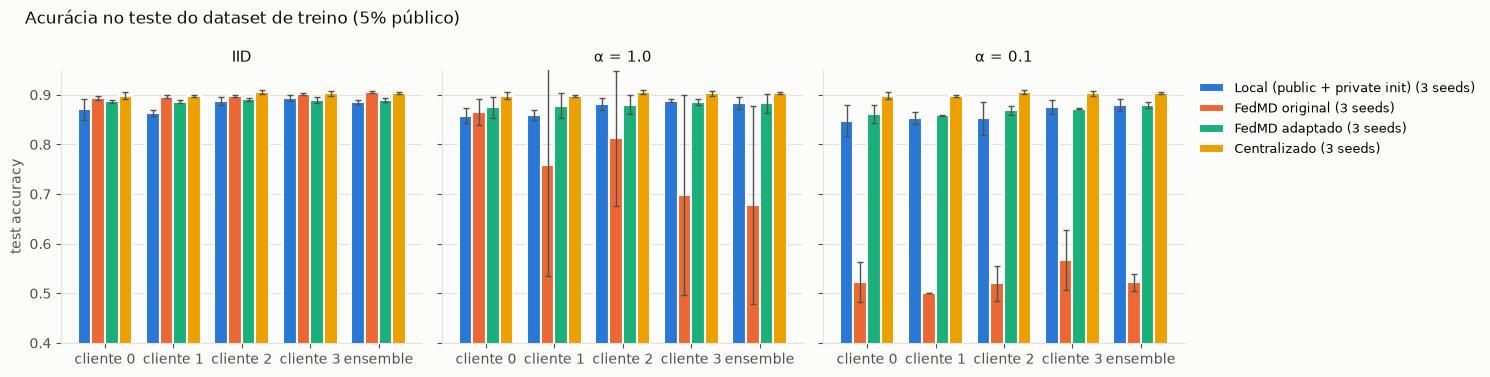

In [2]:
METODOS = ['Local (public + private init)', 'FedMD original', 'FedMD adaptado', 'Centralizado']
METODO_COLOR = dict(zip(METODOS, C))
MODELOS = ['cliente 0', 'cliente 1', 'cliente 2', 'cliente 3', 'ensemble']


def resultados_4_configuracoes():
    """Uma linha por método, alpha, seed e modelo, com acurácia no teste original e no PH2."""
    D = f'{R}/test_models'
    rows = []
    fontes = [('FedMD adaptado', 'adaptado', 'federated', (26, 30)),
              ('Local (public + private init)', 'adaptado', 'private_init', None),
              ('FedMD original', 'original', 'federated', (16, 20))]
    for metodo, prefix, stage, rounds in fontes:
        for seed in (42, 1, 2):
            base = f'{D}/{prefix}_seed{seed}'
            if not os.path.exists(f'{base}_extra_test_metrics.csv'):
                continue  # execução ainda não concluída
            t, e, x = (load(f'{base}_{f}.csv') for f in ('test_metrics', 'ensemble_metrics', 'extra_test_metrics'))
            sel = lambda df: df[(df.stage == stage) & (df['round'].between(*rounds) if rounds else True)]
            t, e, x = sel(t), sel(e), sel(x)
            for alpha in ALPHAS:
                for modelo in MODELOS:
                    xs = x[(x.alpha == alpha) & (x.model == modelo)]
                    if modelo == 'ensemble':
                        test = e[e.alpha == alpha].ensemble_accuracy.mean()
                    else:
                        test = t[(t.alpha == alpha) & (t.client_id == int(modelo[-1]))].test_accuracy.mean()
                    rows.append({'método': metodo, 'alpha': alpha, 'seed': seed, 'modelo': modelo, 'test_accuracy': test,
                                 'ph2_accuracy': xs.accuracy.mean(), 'ph2_balanced_accuracy': xs.balanced_accuracy.mean()})
    if os.path.exists(f'{D}/centralizado.csv'):
        c = pd.read_csv(f'{D}/centralizado.csv')
        for _, r in c.iterrows():
            modelo = 'ensemble' if r.model == 'ensemble' else r.model.replace('arquitetura', 'cliente')
            for alpha in ALPHAS:  # o centralizado não depende de alpha: repetido em cada painel
                rows.append({'método': 'Centralizado', 'alpha': alpha, 'seed': r.seed, 'modelo': modelo,
                             'test_accuracy': r.test_accuracy, 'ph2_accuracy': r.ph2_accuracy,
                             'ph2_balanced_accuracy': r.ph2_balanced_accuracy})
    return pd.DataFrame(rows)


def barras_por_cliente(df, metrica, titulo, ylim, referencia=None, nome=None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    metodos = [m for m in METODOS if m in set(df['método'])]
    largura = 0.8 / len(metodos)
    xs = np.arange(len(MODELOS))
    for ax, alpha in zip(axes, ALPHAS):
        for i, metodo in enumerate(metodos):
            g = df[(df['método'] == metodo) & (df.alpha == alpha)].groupby('modelo')[metrica]
            m, s, n = g.mean().reindex(MODELOS), g.std().reindex(MODELOS), g.count().max()
            ax.bar(xs + (i - (len(metodos) - 1) / 2) * largura, m, largura, yerr=s if n > 1 else None,
                   color=METODO_COLOR[metodo], edgecolor=SURFACE, linewidth=1.5,
                   error_kw={'ecolor': MUTED, 'elinewidth': 1, 'capsize': 2}, label=f'{metodo} ({n} seed{"s" if n > 1 else ""})')
        if referencia is not None:
            ax.axhline(referencia[0], color=MUTED, ls=':', lw=1)
            ax.text(len(MODELOS) - 0.5, referencia[0], referencia[1], color=MUTED, fontsize=8, ha='right', va='bottom')
        ax.set_xticks(xs, MODELOS)
        ax.set_ylim(*ylim)
        ax.set_title(ALPHA_LABEL[alpha])
    axes[0].set_ylabel(metrica.replace('_', ' '))
    axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    if nome:
        save(fig, nome)
    plt.show()


quatro = resultados_4_configuracoes()
barras_por_cliente(quatro, 'test_accuracy', 'Acurácia no teste do dataset de treino (5% público)', (0.4, 0.95),
                   nome='1_teste_por_cliente')

### Avaliação externa: PH2

No PH2, 80% das imagens são benignas, então prever "benigno" para tudo já dá 0,80 de acurácia (linha pontilhada). A acurácia balanceada, que é a média do recall de cada classe, dá 0,5 para esse modelo trivial e é a métrica mais justa para esse dataset.

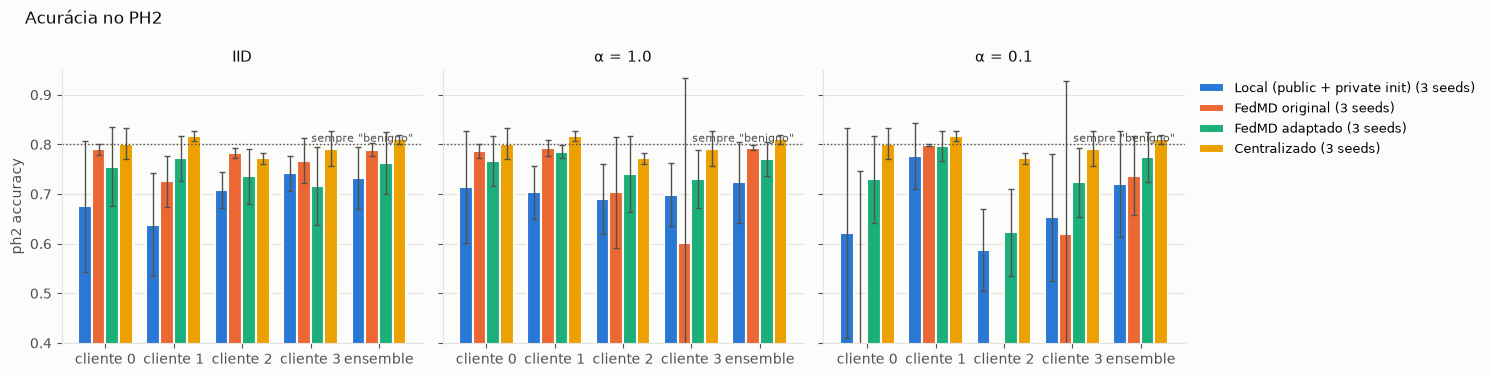

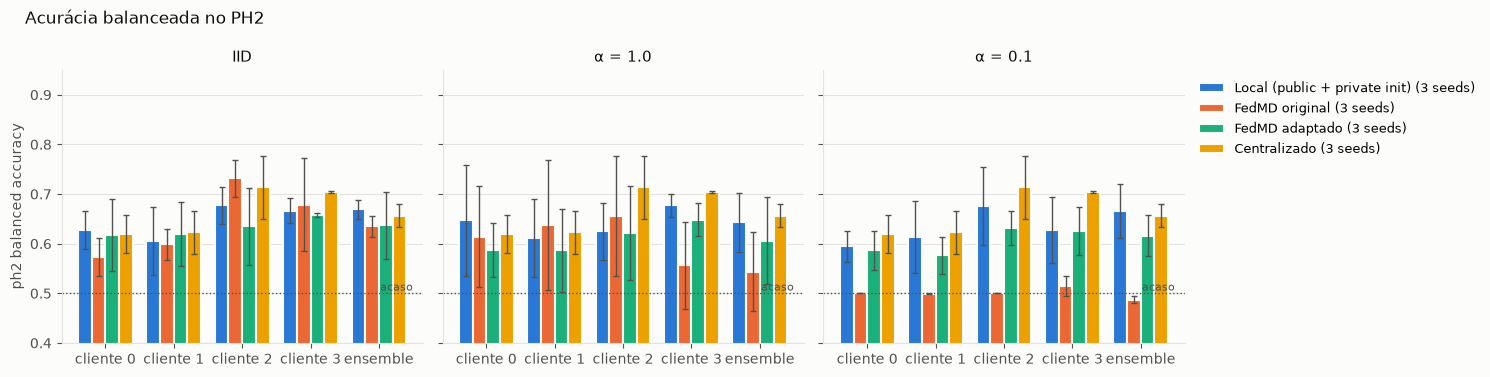

In [3]:
barras_por_cliente(quatro, 'ph2_accuracy', 'Acurácia no PH2', (0.4, 0.95), referencia=(0.80, 'sempre "benigno"'),
                   nome='1_ph2_acuracia_por_cliente')
barras_por_cliente(quatro, 'ph2_balanced_accuracy', 'Acurácia balanceada no PH2', (0.4, 0.95),
                   referencia=(0.5, 'acaso'), nome='1_ph2_balanceada_por_cliente')

## 2. Etapas do desenvolvimento incremental

Média de acurácia dos 4 clientes no teste. Cada painel é uma fração pública, e cada linha é uma divisão dos dados privados. As etapas 1 a 5 e 7 a 9 usam frações de 10%, 40% e 80%, com seed 42, a menos que outra seed esteja indicada. A linha tracejada separa a inicialização das rodadas federadas.

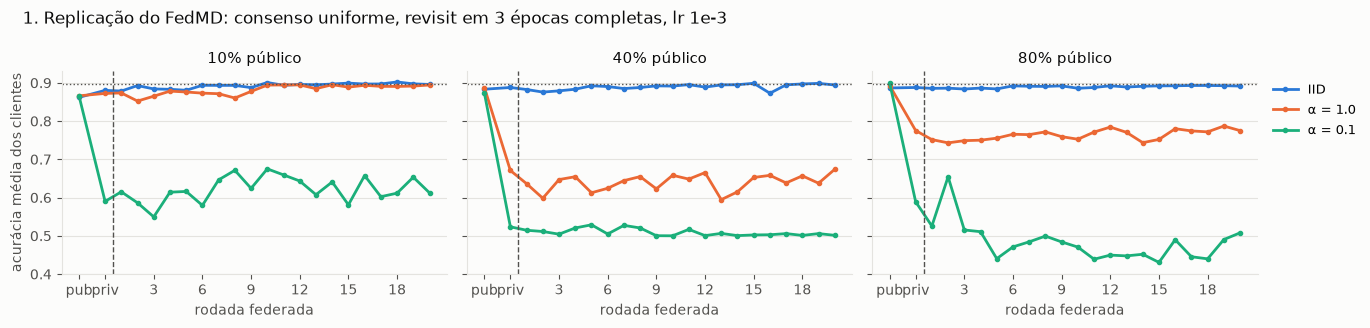

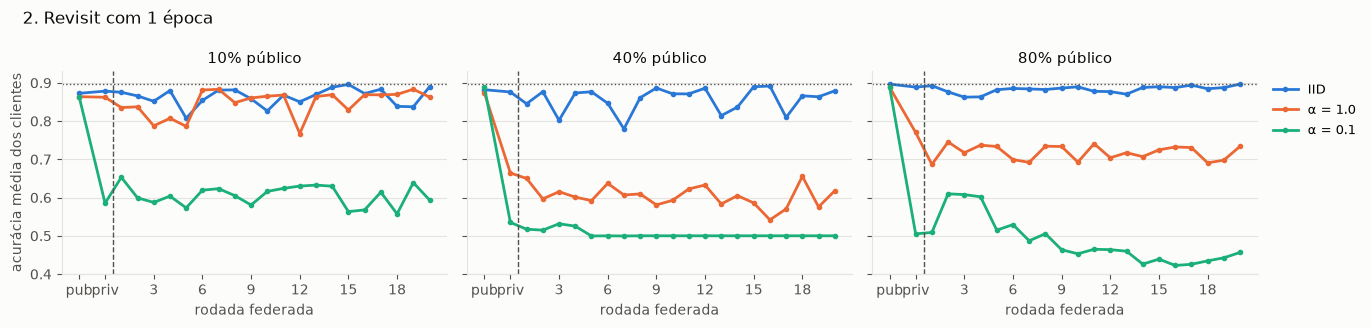

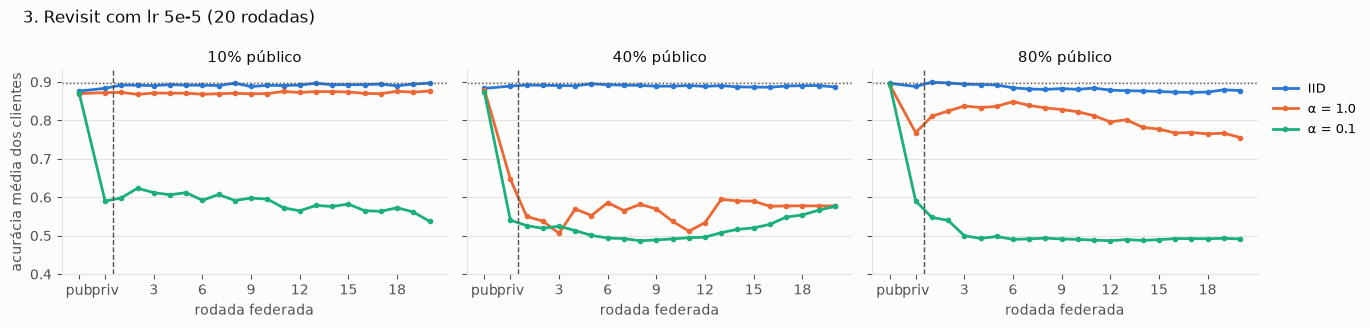

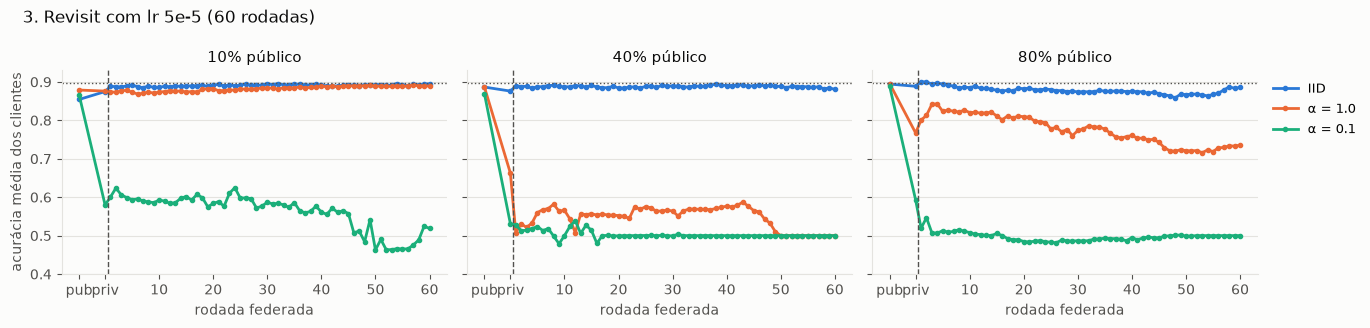

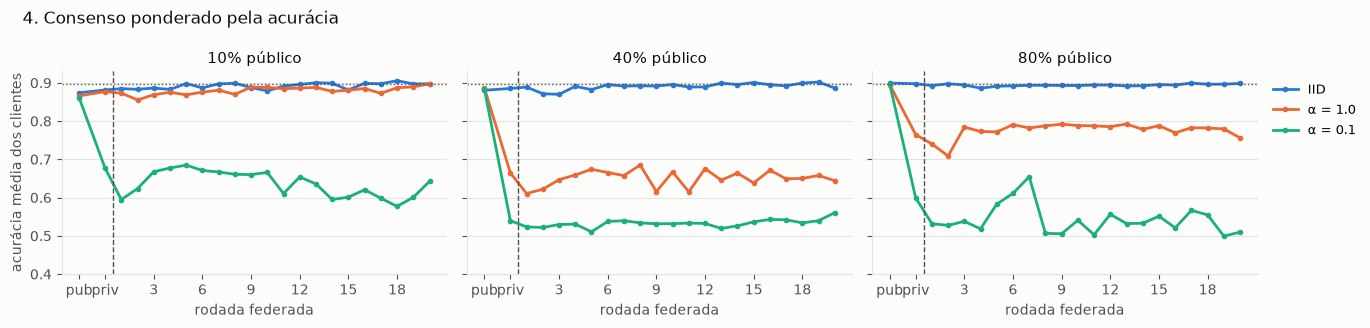

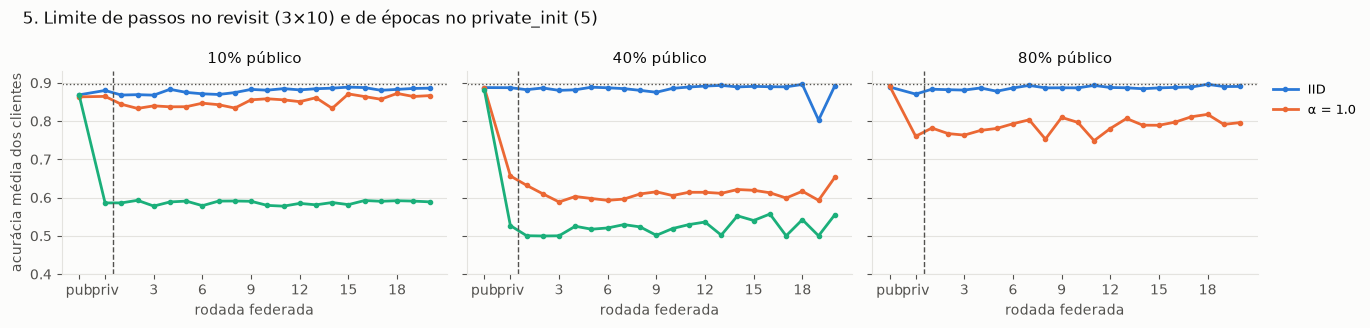

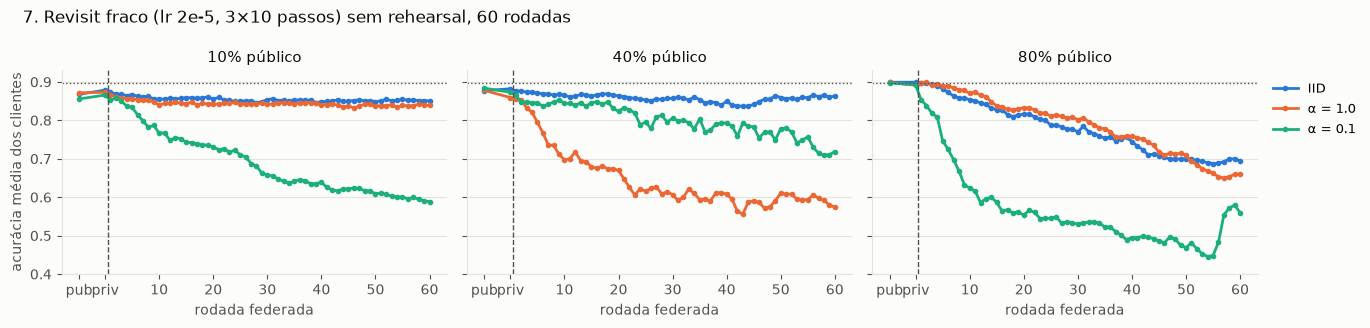

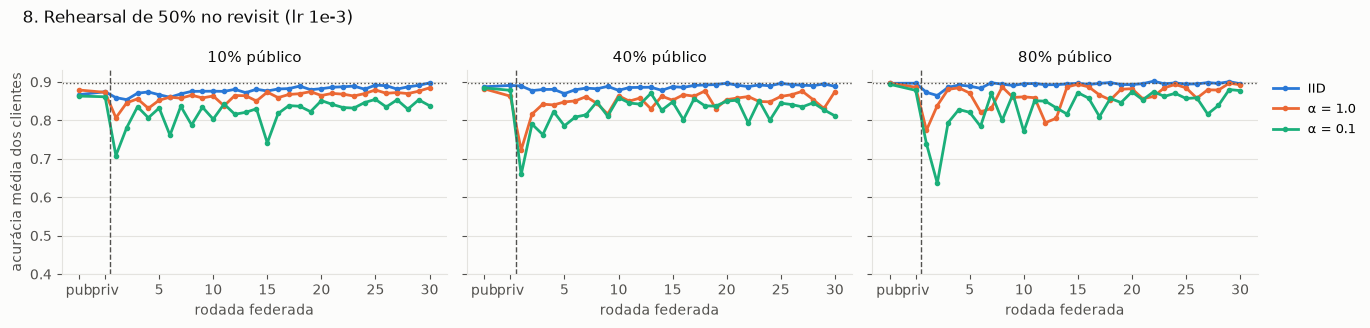

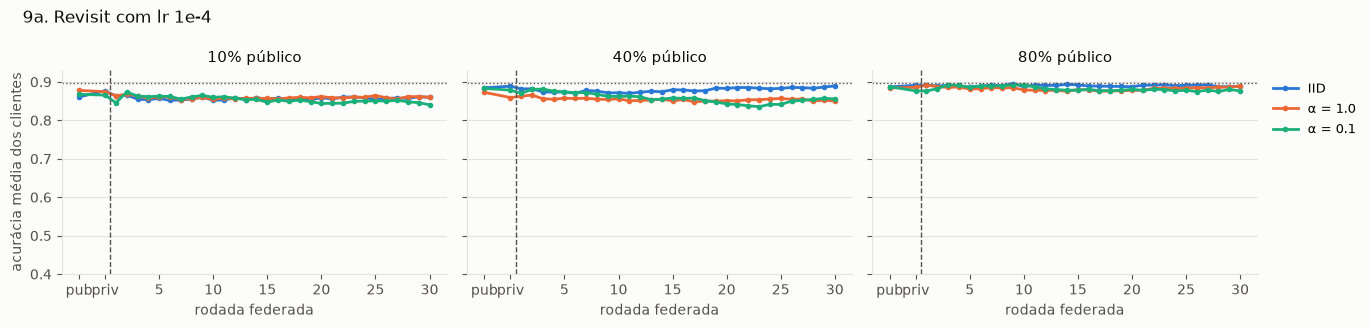

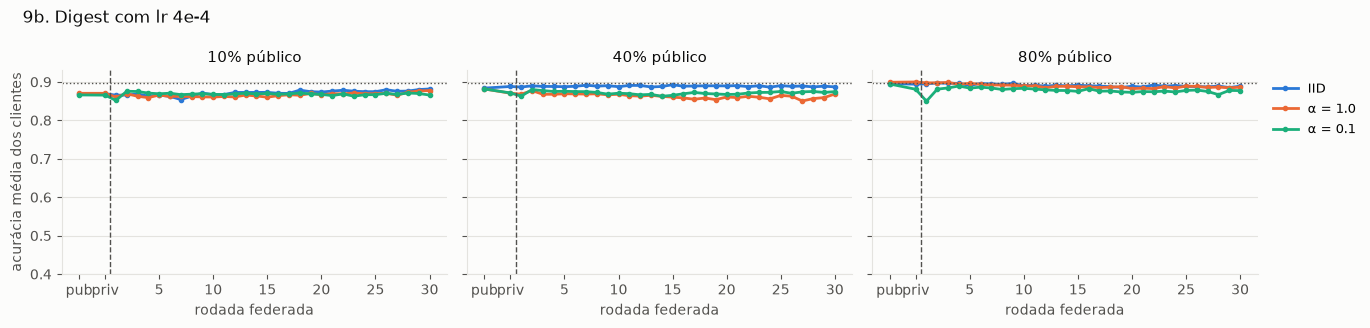

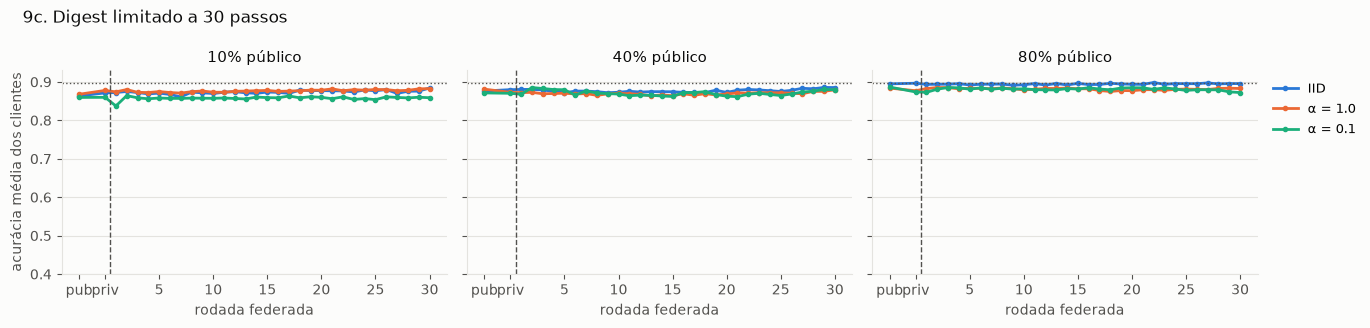

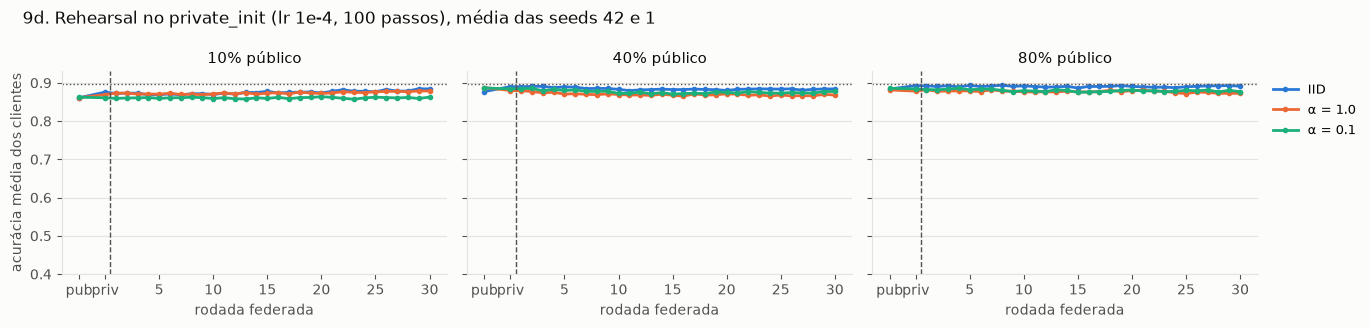

In [4]:
def curva(t):
    """Média dos clientes por fração, alpha e momento de avaliação (-1 = pub, 0 = priv, k = rodada k)."""
    t = t.copy()
    t['ponto'] = np.select([t.stage == 'public_init', t.stage == 'private_init'], [-1, 0], t['round']).astype(float)
    return t.groupby(['public_fraction', 'alpha', 'ponto']).test_accuracy.mean().reset_index()


def plot_etapa(nome, titulo, paths):
    c = curva(pd.concat([load(p) for p in paths]))
    fracs = sorted(c.public_fraction.unique())
    fig, axes = plt.subplots(1, len(fracs), figsize=(4.6 * len(fracs), 3.3), sharey=True, squeeze=False)
    ultimo = int(c.ponto.max())
    gap = max(1.5, 0.08 * ultimo)  # distância visual entre pub e priv, proporcional ao número de rodadas
    c.loc[c.ponto == -1, 'ponto'] = -gap
    passo = max(1, ultimo // 6)
    ticks = list(range(passo, ultimo + 1, passo))
    for ax, f in zip(axes[0], fracs):
        for alpha in ALPHAS:
            s = c[(c.public_fraction == f) & (c.alpha == alpha)]
            if not s.empty:
                ax.plot(s.ponto, s.test_accuracy, color=ALPHA_COLOR[alpha], marker='o', ms=3, label=ALPHA_LABEL[alpha])
        ax.axvline(0.5, color=MUTED, ls='--', lw=1)
        ax.axhline(TETO, color=MUTED, ls=':', lw=1)
        ax.set_xticks([-gap, 0] + ticks, ['pub', 'priv'] + [str(k) for k in ticks])
        ax.set_ylim(0.4, 0.93)
        ax.set_xlabel('rodada federada')
        ax.set_title(f'{f * 100:g}% público')
    axes[0][0].set_ylabel('acurácia média dos clientes')
    axes[0][-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    save(fig, f'2_etapa_{nome}')
    plt.show()


ETAPAS = [
    ('01', '1. Replicação do FedMD: consenso uniforme, revisit em 3 épocas completas, lr 1e-3',
     ['01_replicacao_fedmd/test_metrics_3_private_epoch.csv']),
    ('02', '2. Revisit com 1 época', ['02_revisit_1_epoca/test_metrics_1_private_epoch.csv']),
    ('03a', '3. Revisit com lr 5e-5 (20 rodadas)', ['03_revisit_lr_5e-5/test_metrics_3_private_epoch_lr5e-5.csv']),
    ('03b', '3. Revisit com lr 5e-5 (60 rodadas)', ['03_revisit_lr_5e-5/test_metrics_3_private_epoch_lr5e-5_60_rounds.csv']),
    ('04', '4. Consenso ponderado pela acurácia', ['04_consenso_ponderado/test_metrics_3_private_epoch_weighted.csv']),
    ('05', '5. Limite de passos no revisit (3×10) e de épocas no private_init (5)',
     ['05_limite_passos_revisit_private_init/test_metrics_3_private_epoch_weighted_10_steps_init5.csv']),
    ('07', '7. Revisit fraco (lr 2e-5, 3×10 passos) sem rehearsal, 60 rodadas', ['07_revisit_fraco_sem_rehearsal/cen2_test_metrics.csv']),
    ('08', '8. Rehearsal de 50% no revisit (lr 1e-3)', ['08_rehearsal_no_revisit/cen3_test_metrics.csv']),
    ('09a', '9a. Revisit com lr 1e-4', ['09a_revisit_lr_1e-4/lr1e-4_test_metrics.csv']),
    ('09b', '9b. Digest com lr 4e-4', ['09b_digest_lr_4e-4/lr4e-4_test_metrics.csv']),
    ('09c', '9c. Digest limitado a 30 passos', ['09c_digest_30_passos/steps30_test_metrics.csv']),
    ('09d', '9d. Rehearsal no private_init (lr 1e-4, 100 passos), média das seeds 42 e 1',
     ['09d_rehearsal_private_init/B_init1e-4_seed42_test_metrics.csv', '09d_rehearsal_private_init/C_init1e-4_seed1_test_metrics.csv']),
]
for nome, titulo, arquivos in ETAPAS:
    plot_etapa(nome, titulo, [f'{R}/{a}' for a in arquivos])

### Etapa 6: varredura do `private_init` (sem rodadas federadas)

Variação da acurácia de cada cliente entre o `public_init` e o `private_init`. As barras mostram a média dos 36 clientes (9 configurações × 4), e os pontos, o pior cliente. A linha tracejada é o critério de quebra (−0,05).

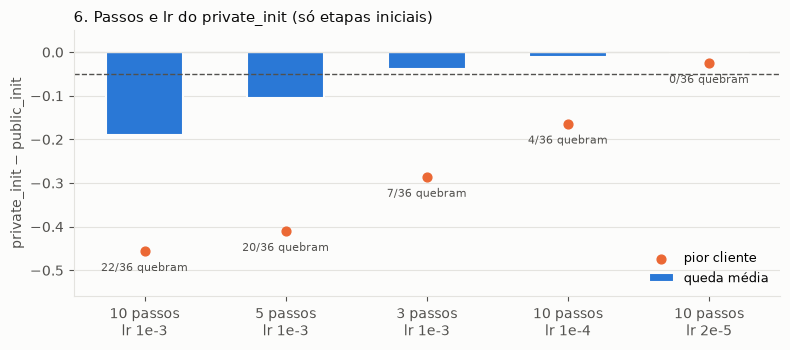

In [5]:
VARREDURA = [('cen1_init10', '10 passos\nlr 1e-3'), ('cen1_init5', '5 passos\nlr 1e-3'), ('cen1_init3', '3 passos\nlr 1e-3'),
             ('cen1_init10_lr1e-4', '10 passos\nlr 1e-4'), ('cen1_init10_lr2e-5', '10 passos\nlr 2e-5')]
k = ['public_fraction', 'alpha', 'client_id']
linhas = []
for prefixo, rotulo in VARREDURA:
    t = load(f'{R}/06_private_init_10_passos_lr_2e-5/{prefixo}_test_metrics.csv')
    d = t[t.stage == 'private_init'].set_index(k).test_accuracy - t[t.stage == 'public_init'].set_index(k).test_accuracy
    linhas.append({'teste': rotulo, 'média': d.mean(), 'pior': d.min(), 'quebram': int((d < -0.05).sum())})
v = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(len(v))
ax.bar(xs, v['média'], 0.55, color=C[0], edgecolor=SURFACE, linewidth=1.5, label='queda média')
ax.scatter(xs, v['pior'], color=C[1], s=40, zorder=3, label='pior cliente')
for x, (_, r) in zip(xs, v.iterrows()):
    ax.text(x, r['pior'] - 0.025, f"{r['quebram']}/36 quebram", ha='center', va='top', fontsize=8, color=MUTED)
ax.axhline(-0.05, color=MUTED, ls='--', lw=1)
ax.axhline(0, color=GRID, lw=1)
ax.set_xticks(xs, v['teste'])
ax.set_ylim(-0.56, 0.05)
ax.set_ylabel('private_init − public_init')
ax.legend(loc='lower right', fontsize=9)
ax.set_title('6. Passos e lr do private_init (só etapas iniciais)', loc='left')
fig.tight_layout()
save(fig, '2_etapa_06')
plt.show()

## 3. Treino local (public + private init) em cada cenário

Configuração final, com média ± desvio padrão de 3 seeds. As barras mostram a acurácia logo após o `public_init` e após o `public_init` + `private_init`, que é a linha de base do estudo.

Fontes:
- 1% e 5%: `ensemble_e_leave_one_out` (`all_*`)
- 20%: `fracoes_publicas_5_e_20` (seeds 42 e 1) e `experimento_final` (seed 2)

O `public_init` e o `private_init` são os mesmos nessas execuções. Elas só diferem no digest, que não afeta estas etapas.

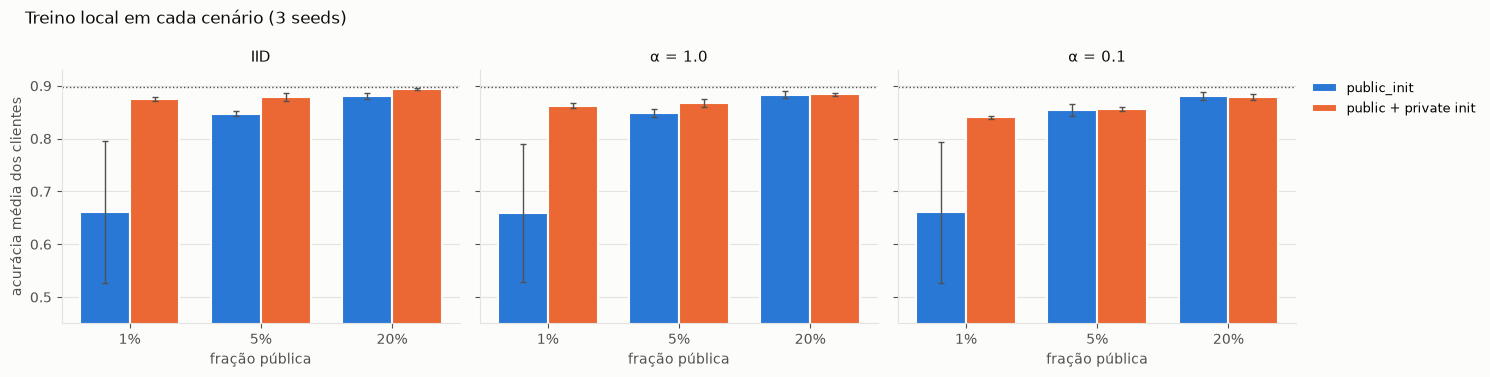

etapa         public + private init  public_init
fração alpha                                    
0.01   0.1                    0.840        0.660
       1.0                    0.862        0.659
       iid                    0.875        0.662
0.05   0.1                    0.856        0.854
       1.0                    0.868        0.848
       iid                    0.879        0.847
0.20   0.1                    0.879        0.881
       1.0                    0.884        0.883
       iid                    0.894        0.880

In [6]:
FONTES_LOCAL = {
    0.01: [f'ensemble_e_leave_one_out/all_P01_seed{s}' for s in (42, 1, 2)],
    0.05: [f'ensemble_e_leave_one_out/all_P05_seed{s}' for s in (42, 1, 2)],
    0.2: ['fracoes_publicas_5_e_20/F2_seed42', 'fracoes_publicas_5_e_20/F2_seed1', 'experimento_final/P20_seed2'],
}
linhas = []
for frac, bases in FONTES_LOCAL.items():
    for base in bases:
        t = load(f'{R}/{base}_test_metrics.csv')
        t = t[t.public_fraction == frac]
        for alpha in ALPHAS:
            for stage, rotulo in (('public_init', 'public_init'), ('private_init', 'public + private init')):
                linhas.append({'fração': frac, 'alpha': alpha, 'seed': t.seed.iloc[0], 'etapa': rotulo,
                               'acc': t[(t.alpha == alpha) & (t.stage == stage)].test_accuracy.mean()})
local = pd.DataFrame(linhas)

ETAPAS_LOCAL = ['public_init', 'public + private init']
FRACS = sorted(FONTES_LOCAL)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
xs = np.arange(len(FRACS))
for ax, alpha in zip(axes, ALPHAS):
    for i, etapa in enumerate(ETAPAS_LOCAL):
        g = local[(local.alpha == alpha) & (local.etapa == etapa)].groupby('fração').acc
        ax.bar(xs + (i - 0.5) * 0.38, g.mean().reindex(FRACS), 0.38, yerr=g.std().reindex(FRACS), color=C[i],
               edgecolor=SURFACE, linewidth=1.5, error_kw={'ecolor': MUTED, 'elinewidth': 1, 'capsize': 2}, label=etapa)
    ax.axhline(TETO, color=MUTED, ls=':', lw=1)
    ax.set_xticks(xs, [f'{f * 100:g}%' for f in FRACS])
    ax.set_xlabel('fração pública')
    ax.set_ylim(0.45, 0.93)
    ax.set_title(ALPHA_LABEL[alpha])
axes[0].set_ylabel('acurácia média dos clientes')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
fig.suptitle('Treino local em cada cenário (3 seeds)', color=TEXT, x=0.02, ha='left')
fig.tight_layout()
save(fig, '3_local_por_cenario')
plt.show()

local.pivot_table(index=['fração', 'alpha'], columns='etapa', values='acc', aggfunc='mean').round(3)

## 4. Ganho do FedMD adaptado em função da fração pública

Ganho = média dos 4 clientes nas rodadas 26–30 menos a média logo após o `private_init` (treino local), na mesma execução. Cada ponto é a média ± desvio padrão entre as seeds. A linha tracejada marca ganho zero.

Duas variantes do digest:
- **KL (T = 4):** 1% e 5% em `ensemble_e_leave_one_out` (`all_*`); 10%, 40% e 80% em `fracoes_publicas_10_40_80` (3 seeds).
- **MAE:** 1%, 5% e 20% do experimento final (3 seeds); 10%, 40% e 80% em `digest_kl_10_40_80` (seeds 42 e 1).

Com 20% só existe a execução com MAE.

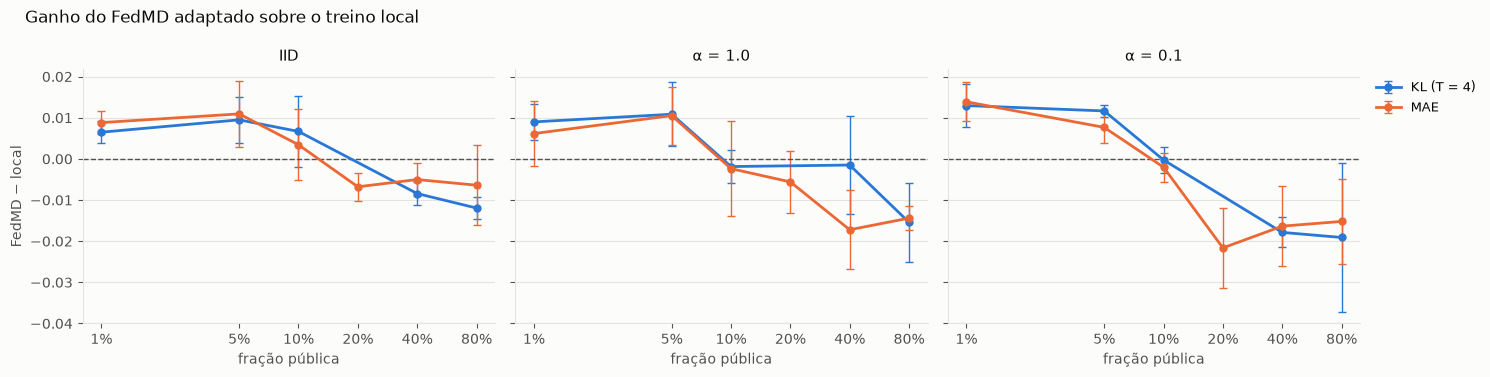

ganho  desvio  seeds pares_com_ganho
digest     fração                                      
KL (T = 4) 0.01    0.009   0.005      3             9/9
           0.05    0.011   0.005      3             9/9
           0.10    0.002   0.006      3             6/9
           0.40   -0.009   0.010      3             1/9
           0.80   -0.015   0.011      3             0/9
MAE        0.01    0.010   0.006      3             8/9
           0.05    0.010   0.006      3             9/9
           0.10   -0.000   0.007      2             3/6
           0.20   -0.011   0.010      3             1/9
           0.40   -0.013   0.009      2             0/6
           0.80   -0.012   0.008      2             1/6

In [7]:
FONTES_GANHO = {
    'KL (T = 4)': {
        0.01: [f'ensemble_e_leave_one_out/all_P01_seed{s}' for s in (42, 1, 2)],
        0.05: [f'ensemble_e_leave_one_out/all_P05_seed{s}' for s in (42, 1, 2)],
        0.1: [f'fracoes_publicas_10_40_80/adaptado_P10_seed{s}' for s in (42, 1, 2)],
        0.4: [f'fracoes_publicas_10_40_80/adaptado_P40_seed{s}' for s in (42, 1, 2)],
        0.8: [f'fracoes_publicas_10_40_80/adaptado_P80_seed{s}' for s in (42, 1, 2)],
    },
    'MAE': {
        0.01: [f'experimento_final/P01_seed{s}' for s in (42, 1, 2)],
        0.05: ['fracoes_publicas_5_e_20/F2b_seed42', 'fracoes_publicas_5_e_20/F2b_seed1', 'experimento_final/P05_seed2'],
        0.1: [f'digest_kl_10_40_80/MAE_P10_seed{s}' for s in (42, 1)],
        0.2: ['fracoes_publicas_5_e_20/F2_seed42', 'fracoes_publicas_5_e_20/F2_seed1', 'experimento_final/P20_seed2'],
        0.4: [f'digest_kl_10_40_80/MAE_P40_seed{s}' for s in (42, 1)],
        0.8: [f'digest_kl_10_40_80/MAE_P80_seed{s}' for s in (42, 1)],
    },
}
DIGEST_COLOR = {'KL (T = 4)': C[0], 'MAE': C[1]}

linhas = []
for digest, fontes in FONTES_GANHO.items():
    for frac, bases in fontes.items():
        for base in bases:
            path = f'{R}/{base}_test_metrics.csv'
            if not os.path.exists(path):
                continue  # execução ainda não concluída
            t = load(path)
            t = t[t.public_fraction == frac]
            for alpha in ALPHAS:
                a = t[t.alpha == alpha]
                local = a[a.stage == 'private_init'].test_accuracy.mean()
                fedmd = a[(a.stage == 'federated') & (a['round'].between(26, 30))].test_accuracy.mean()
                linhas.append({'digest': digest, 'fração': frac, 'alpha': alpha, 'seed': t.seed.iloc[0],
                               'local': local, 'FedMD': fedmd, 'ganho': fedmd - local})
ganhos = pd.DataFrame(linhas)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, alpha in zip(axes, ALPHAS):
    for digest in FONTES_GANHO:
        g = ganhos[(ganhos.digest == digest) & (ganhos.alpha == alpha)].groupby('fração').ganho
        m, s = g.mean(), g.std()
        ax.errorbar(m.index * 100, m, yerr=s, color=DIGEST_COLOR[digest], marker='o', ms=5, capsize=3,
                    elinewidth=1, label=digest)
    ax.axhline(0, color=MUTED, ls='--', lw=1)
    ax.set_xscale('log')
    fracs = sorted(ganhos.fração.unique())
    ax.set_xticks([f * 100 for f in fracs], [f'{f * 100:g}%' for f in fracs])
    ax.minorticks_off()
    ax.set_xlabel('fração pública')
    ax.set_title(ALPHA_LABEL[alpha])
axes[0].set_ylabel('FedMD − local')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
fig.suptitle('Ganho do FedMD adaptado sobre o treino local', color=TEXT, x=0.02, ha='left')
fig.tight_layout()
save(fig, '4_ganho_por_fracao')
plt.show()

resumo_ganho = ganhos.groupby(['digest', 'fração']).agg(
    ganho=('ganho', 'mean'), desvio=('ganho', 'std'), seeds=('seed', 'nunique'),
    pares_com_ganho=('ganho', lambda g: f'{(g > 0).sum()}/{len(g)}')).round(3)
resumo_ganho

### KL × MAE por par

Diferença KL − MAE no ganho, para cada fração, α e seed em que os dois lados existem (mesma seed e mesma divisão dos dados).

In [8]:
par = ganhos.pivot_table(index=['fração', 'alpha', 'seed'], columns='digest', values='ganho').dropna()
par['KL − MAE'] = par['KL (T = 4)'] - par['MAE']
par.groupby('fração')['KL − MAE'].agg(['mean', 'std', 'count', lambda d: f'{(d > 0).sum()}/{len(d)}']).round(4) \
   .rename(columns={'<lambda_0>': 'KL melhor'})

,mean,std,count,KL melhor
fração,,,,
0.01,-0.0001,0.0033,9,2/9
0.05,0.0010,0.0036,9,6/9
0.10,0.0024,0.0036,6,5/6
0.40,0.0048,0.0106,6,4/6
0.80,-0.0010,0.0075,6,4/6


## 5. Os métodos em cada fração pública

Mesma comparação da seção 1 (média dos 4 clientes), agora em cada fração pública: 5% em `test_models` e 10%, 40% e 80% em `fracoes_publicas_10_40_80` (3 seeds). O centralizado não depende da fração e aparece como linha de referência.

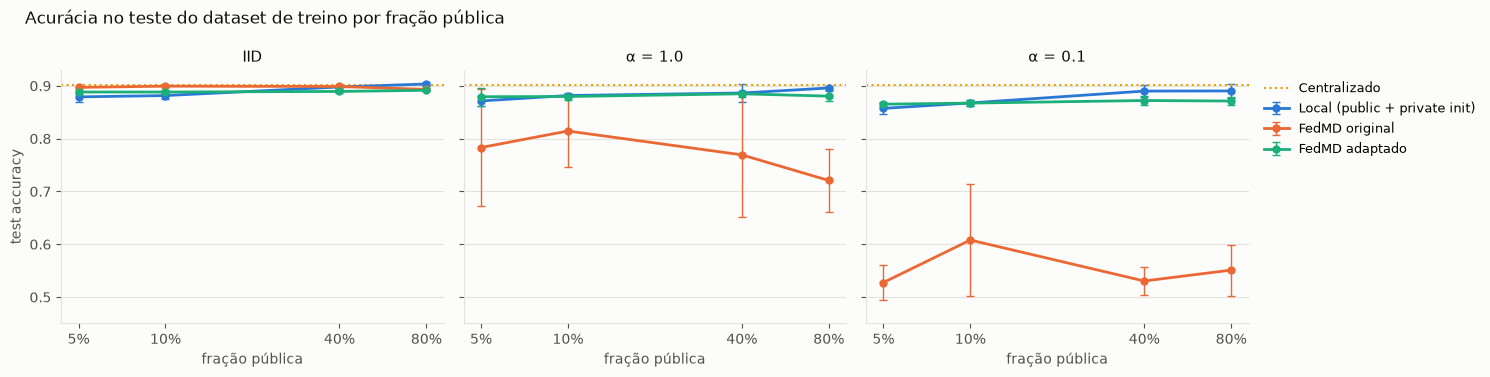

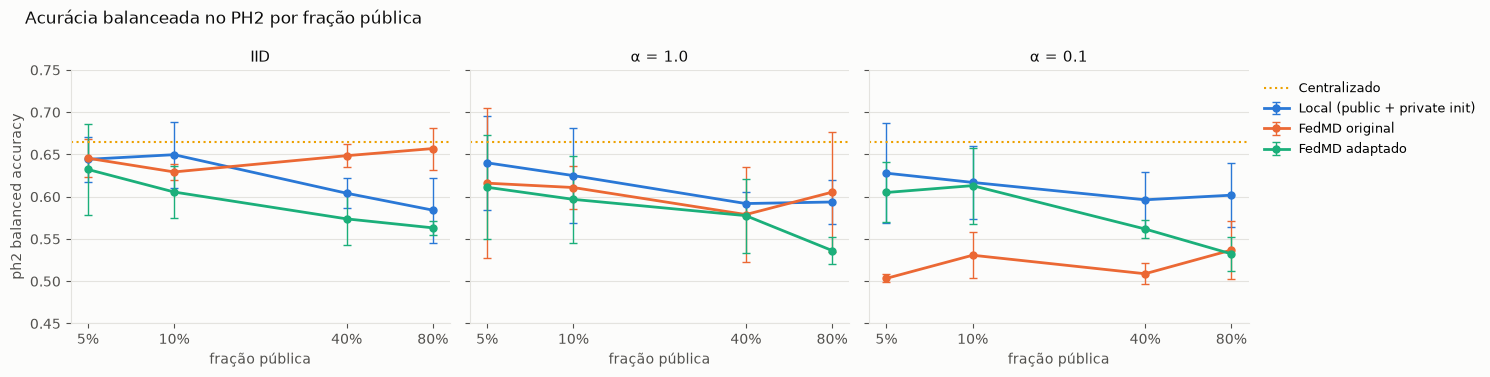

ph2_balanced_accuracy                 \
método              FedMD adaptado FedMD original   
fração alpha                                        
0.05   0.1                   0.605          0.503   
       1.0                   0.611          0.616   
       iid                   0.632          0.646   
0.10   0.1                   0.613          0.531   
       1.0                   0.597          0.611   
       iid                   0.606          0.629   
0.40   0.1                   0.562          0.509   
       1.0                   0.578          0.579   
       iid                   0.574          0.649   
0.80   0.1                   0.532          0.537   
       1.0                   0.536          0.605   
       iid                   0.563          0.657   

                                            test_accuracy                 \
método       Local (public + private init) FedMD adaptado FedMD original   
fração alpha                                                               
0.05   0.1                           0.628          0.865          0.528   
       1.0                           0.640          0.879          0.783   
       iid                           0.644          0.888          0.897   
0.10   0.1                           0.617          0.867          0.608   
       1.0                           0.625          0.880          0.814   
       iid                           0.650          0.888          0.899   
0.40   0.1                           0.596          0.872          0.530   
       1.0                           0.592          0.885          0.769   
       iid                           0.604          0.889          0.899   
0.80   0.1                           0.602          0.871          0.551   
       1.0                           0.594          0.880          0.721   
       iid                           0.584          0.891          0.893   

                                            
método       Local (public + private init)  
fração alpha                                
0.05   0.1                           0.857  
       1.0                           0.871  
       iid                           0.879  
0.10   0.1                           0.867  
       1.0                           0.882  
       iid                           0.881  
0.40   0.1                           0.890  
       1.0                           0.886  
       iid                           0.898  
0.80   0.1                           0.890  
       1.0                           0.896  
       iid                           0.903

In [9]:
FONTES_METODOS = {0.05: ('test_models', '{m}_seed{s}')}
FONTES_METODOS.update({f: ('fracoes_publicas_10_40_80', '{m}_P' + p + '_seed{s}') for f, p in ((0.1, '10'), (0.4, '40'), (0.8, '80'))})
linhas = []
for frac, (pasta, padrao) in FONTES_METODOS.items():
    for metodo, prefixo, stage, rounds in (('FedMD adaptado', 'adaptado', 'federated', (26, 30)),
                                            ('Local (public + private init)', 'adaptado', 'private_init', None),
                                            ('FedMD original', 'original', 'federated', (16, 20))):
        for seed in (42, 1, 2):
            base = f'{R}/{pasta}/' + padrao.format(m=prefixo, s=seed)
            if not os.path.exists(f'{base}_extra_test_metrics.csv'):
                continue
            t, x = load(f'{base}_test_metrics.csv'), load(f'{base}_extra_test_metrics.csv')
            sel = lambda d: d[(d.stage == stage) & (d['round'].between(*rounds) if rounds else True)]
            t, x = sel(t), sel(x)
            x = x[x.model != 'ensemble']
            for alpha in ALPHAS:
                linhas.append({'fração': frac, 'método': metodo, 'alpha': alpha, 'seed': seed,
                               'test_accuracy': t[t.alpha == alpha].test_accuracy.mean(),
                               'ph2_accuracy': x[x.alpha == alpha].accuracy.mean(),
                               'ph2_balanced_accuracy': x[x.alpha == alpha].balanced_accuracy.mean()})
por_fracao = pd.DataFrame(linhas)
central = quatro[(quatro['método'] == 'Centralizado') & (quatro.modelo != 'ensemble')]


def linhas_por_fracao(metrica, titulo, ylim, nome):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    fracs = sorted(por_fracao.fração.unique())
    for ax, alpha in zip(axes, ALPHAS):
        for metodo in METODOS[:3]:
            g = por_fracao[(por_fracao['método'] == metodo) & (por_fracao.alpha == alpha)].groupby('fração')[metrica]
            m, s = g.mean(), g.std()
            ax.errorbar(m.index * 100, m, yerr=s, color=METODO_COLOR[metodo], marker='o', ms=5, capsize=3,
                        elinewidth=1, label=metodo)
        ax.axhline(central[metrica].mean(), color=METODO_COLOR['Centralizado'], ls=':', lw=1.5, label='Centralizado')
        ax.set_xscale('log')
        ax.set_xticks([f * 100 for f in fracs], [f'{f * 100:g}%' for f in fracs])
        ax.minorticks_off()
        ax.set_ylim(*ylim)
        ax.set_xlabel('fração pública')
        ax.set_title(ALPHA_LABEL[alpha])
    axes[0].set_ylabel(metrica.replace('_', ' '))
    axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    save(fig, nome)
    plt.show()


linhas_por_fracao('test_accuracy', 'Acurácia no teste do dataset de treino por fração pública', (0.45, 0.93), '5_teste_por_fracao')
linhas_por_fracao('ph2_balanced_accuracy', 'Acurácia balanceada no PH2 por fração pública', (0.45, 0.75), '5_ph2_balanceada_por_fracao')
por_fracao.pivot_table(index=['fração', 'alpha'], columns='método', values=['test_accuracy', 'ph2_balanced_accuracy']).round(3)

## 6. Ensemble dos clientes em cada fração pública

Mesmo formato da seção 5, com o **ensemble** dos 4 clientes no lugar da média por cliente. Cada modelo prevê de forma independente e a resposta é a média dos logits dos 4 (voto suave).

- **Ensemble local:** os 4 clientes logo após o `private_init`, sem nenhuma colaboração.
- **Ensemble FedMD adaptado / original:** os mesmos 4 clientes depois das rodadas federadas.

Referências:
- **Centralizado (modelo único):** média das 4 arquiteturas, cada uma treinada sozinha com todo o conjunto de treino. Linha pontilhada.
- **Centralizado (ensemble):** ensemble dessas 4 arquiteturas. Linha tracejada.

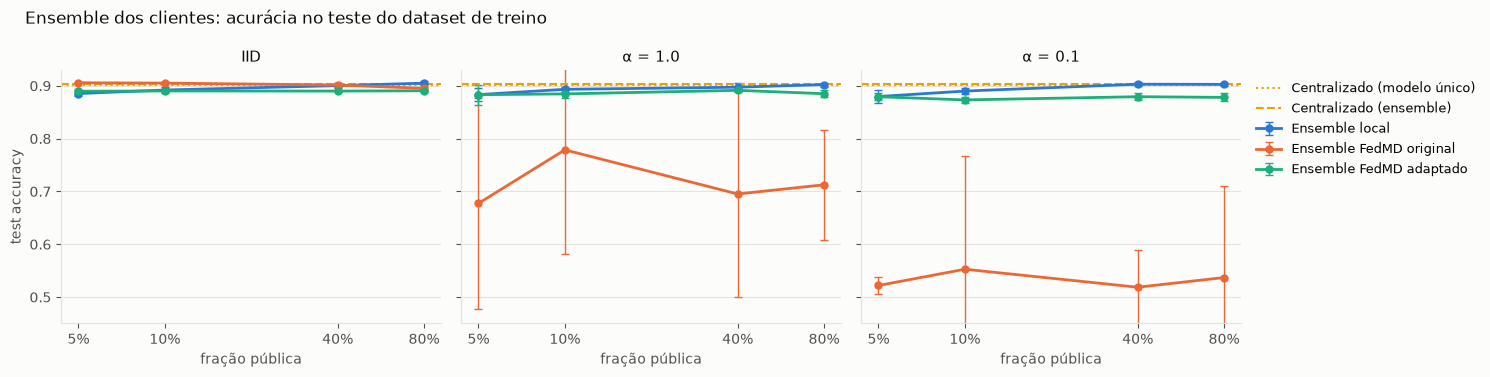

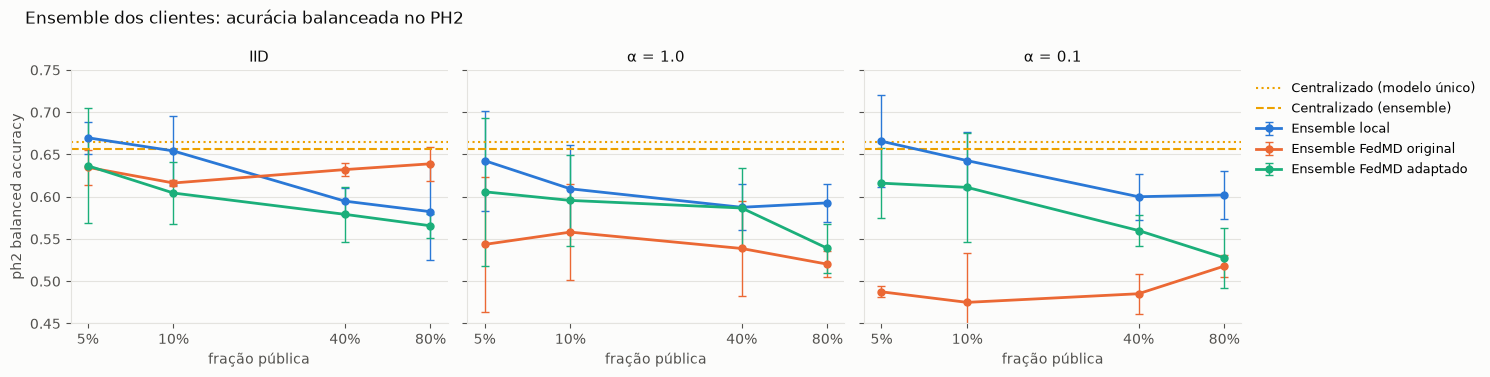

ph2_balanced_accuracy                                         \
ensemble     Ensemble FedMD adaptado Ensemble FedMD original Ensemble local   
fração alpha                                                                  
0.05   0.1                     0.616                   0.488          0.666   
       1.0                     0.606                   0.544          0.643   
       iid                     0.637                   0.635          0.670   
0.10   0.1                     0.611                   0.475          0.643   
       1.0                     0.596                   0.558          0.609   
       iid                     0.604                   0.616          0.654   
0.40   0.1                     0.560                   0.485          0.600   
       1.0                     0.587                   0.539          0.588   
       iid                     0.579                   0.632          0.595   
0.80   0.1                     0.528                   0.518          0.602   
       1.0                     0.539                   0.520          0.593   
       iid                     0.566                   0.639          0.582   

                       test_accuracy                                         
ensemble     Ensemble FedMD adaptado Ensemble FedMD original Ensemble local  
fração alpha                                                                 
0.05   0.1                     0.879                   0.522          0.880  
       1.0                     0.883                   0.677          0.883  
       iid                     0.890                   0.906          0.885  
0.10   0.1                     0.873                   0.553          0.890  
       1.0                     0.885                   0.779          0.893  
       iid                     0.890                   0.905          0.892  
0.40   0.1                     0.879                   0.519          0.903  
       1.0                     0.891                   0.695          0.897  
       iid                     0.890                   0.901          0.900  
0.80   0.1                     0.878                   0.537          0.903  
       1.0                     0.885                   0.713          0.902  
       iid                     0.891                   0.895          0.905

In [10]:
ENSEMBLES = {'Ensemble local': 'Local (public + private init)', 'Ensemble FedMD original': 'FedMD original',
             'Ensemble FedMD adaptado': 'FedMD adaptado'}
linhas = []
for frac, (pasta, padrao) in FONTES_METODOS.items():
    for nome, prefixo, stage, rounds in (('Ensemble FedMD adaptado', 'adaptado', 'federated', (26, 30)),
                                          ('Ensemble local', 'adaptado', 'private_init', None),
                                          ('Ensemble FedMD original', 'original', 'federated', (16, 20))):
        for seed in (42, 1, 2):
            base = f'{R}/{pasta}/' + padrao.format(m=prefixo, s=seed)
            if not os.path.exists(f'{base}_extra_test_metrics.csv'):
                continue
            e, x = load(f'{base}_ensemble_metrics.csv'), load(f'{base}_extra_test_metrics.csv')
            sel = lambda d: d[(d.stage == stage) & (d['round'].between(*rounds) if rounds else True)]
            e, x = sel(e), sel(x)
            x = x[x.model == 'ensemble']
            for alpha in ALPHAS:
                linhas.append({'fração': frac, 'ensemble': nome, 'alpha': alpha, 'seed': seed,
                               'test_accuracy': e[e.alpha == alpha].ensemble_accuracy.mean(),
                               'ph2_balanced_accuracy': x[x.alpha == alpha].balanced_accuracy.mean()})
ensembles = pd.DataFrame(linhas)
centralizado = pd.read_csv(f'{R}/test_models/centralizado.csv')
REFERENCIAS = [('Centralizado (modelo único)', centralizado[centralizado.model != 'ensemble'], ':'),
               ('Centralizado (ensemble)', centralizado[centralizado.model == 'ensemble'], '--')]


def ensembles_por_fracao(metrica, titulo, ylim, nome):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    fracs = sorted(ensembles.fração.unique())
    for ax, alpha in zip(axes, ALPHAS):
        for ens, metodo in ENSEMBLES.items():
            g = ensembles[(ensembles.ensemble == ens) & (ensembles.alpha == alpha)].groupby('fração')[metrica]
            m, s = g.mean(), g.std()
            ax.errorbar(m.index * 100, m, yerr=s, color=METODO_COLOR[metodo], marker='o', ms=5, capsize=3,
                        elinewidth=1, label=ens)
        for rotulo, ref, estilo in REFERENCIAS:
            ax.axhline(ref[metrica].mean(), color=METODO_COLOR['Centralizado'], ls=estilo, lw=1.5, label=rotulo)
        ax.set_xscale('log')
        ax.set_xticks([f * 100 for f in fracs], [f'{f * 100:g}%' for f in fracs])
        ax.minorticks_off()
        ax.set_ylim(*ylim)
        ax.set_xlabel('fração pública')
        ax.set_title(ALPHA_LABEL[alpha])
    axes[0].set_ylabel(metrica.replace('_', ' '))
    axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    save(fig, nome)
    plt.show()


ensembles_por_fracao('test_accuracy', 'Ensemble dos clientes: acurácia no teste do dataset de treino', (0.45, 0.93),
                     '6_ensemble_teste_por_fracao')
ensembles_por_fracao('ph2_balanced_accuracy', 'Ensemble dos clientes: acurácia balanceada no PH2', (0.45, 0.75),
                     '6_ensemble_ph2_balanceada_por_fracao')
ensembles.pivot_table(index=['fração', 'alpha'], columns='ensemble', values=['test_accuracy', 'ph2_balanced_accuracy']).round(3)

## 7. Digest ancorado nos rótulos: (1 − w) · KL + w · CE

`results/digest_ce_10_40_80`. O digest mistura a destilação (KL, T = 4) com a entropia cruzada no rótulo verdadeiro das imagens públicas. **w = 1 é o controle sem destilação:** os mesmos passos, só com treino supervisionado. O w = 0 são as execuções KL de `fracoes_publicas_10_40_80`. Seeds 42 e 1, média dos 4 clientes. Ganho = média das rodadas 26–30 menos o `private_init` da mesma execução.

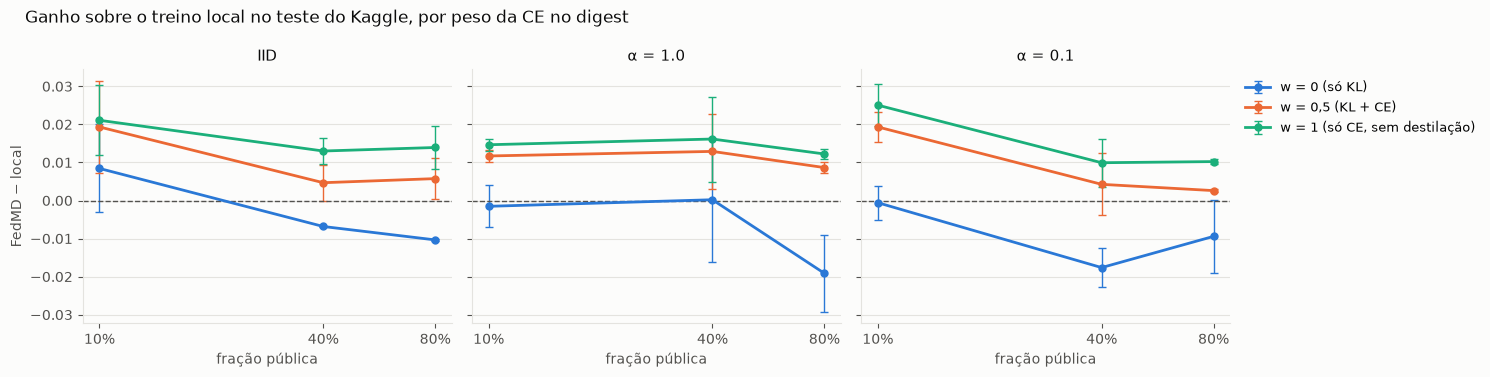

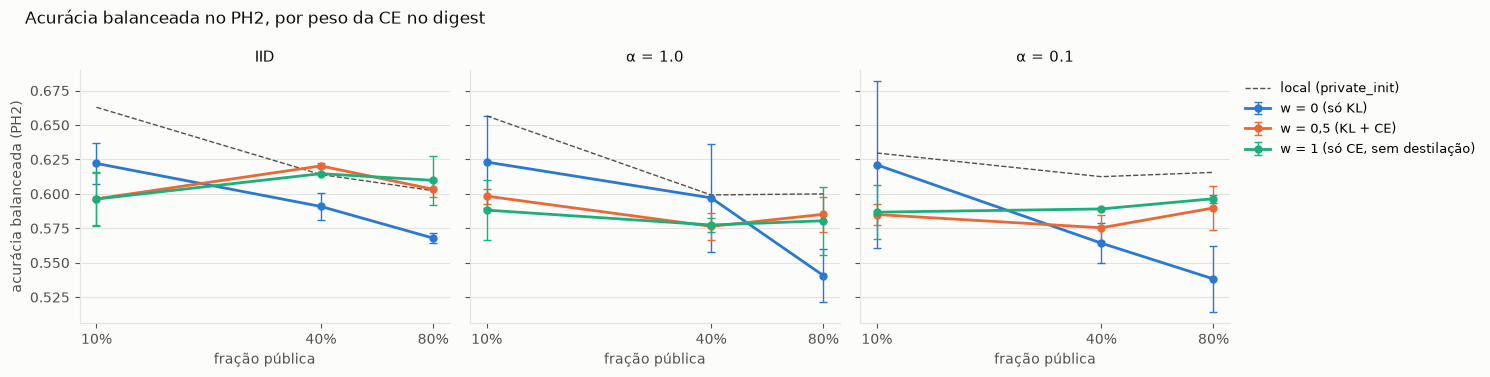

final  ganho  ph2_bal
fração w                         
0.1    0    0.880  0.002    0.622
       0.5  0.893  0.017    0.593
       1    0.897  0.020    0.590
0.4    0    0.882 -0.008    0.584
       0.5  0.896  0.007    0.591
       1    0.902  0.013    0.594
0.8    0    0.882 -0.013    0.549
       0.5  0.901  0.006    0.593
       1    0.905  0.012    0.596

In [11]:
PESOS = {'0': 'w = 0 (só KL)', '0.5': 'w = 0,5 (KL + CE)', '1': 'w = 1 (só CE, sem destilação)'}
PESO_COLOR = dict(zip(PESOS, C))
FONTES_CE = {'0': 'fracoes_publicas_10_40_80/adaptado_P{p}_seed{s}', '0.5': 'digest_ce_10_40_80/CE0.5_P{p}_seed{s}',
             '1': 'digest_ce_10_40_80/CE1.0_P{p}_seed{s}'}
linhas = []
for w, padrao in FONTES_CE.items():
    for frac, p in ((0.1, '10'), (0.4, '40'), (0.8, '80')):
        for seed in (42, 1):
            base = f'{R}/' + padrao.format(p=p, s=seed)
            t, x = load(f'{base}_test_metrics.csv'), load(f'{base}_extra_test_metrics.csv')
            x = x[x.model != 'ensemble']
            fim = lambda d: d[(d.stage == 'federated') & (d['round'].between(26, 30))]
            ini = lambda d: d[d.stage == 'private_init']
            for alpha in ALPHAS:
                ta, xa = t[t.alpha == alpha], x[x.alpha == alpha]
                linhas.append({'w': w, 'fração': frac, 'alpha': alpha, 'seed': seed,
                               'ganho': fim(ta).test_accuracy.mean() - ini(ta).test_accuracy.mean(),
                               'final': fim(ta).test_accuracy.mean(),
                               'ph2_bal': fim(xa).balanced_accuracy.mean(), 'ph2_bal_local': ini(xa).balanced_accuracy.mean()})
ce = pd.DataFrame(linhas)


def linhas_ce(coluna, titulo, ylabel, nome, referencia=None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for ax, alpha in zip(axes, ALPHAS):
        for w, rotulo in PESOS.items():
            g = ce[(ce.w == w) & (ce.alpha == alpha)].groupby('fração')[coluna]
            m, s = g.mean(), g.std()
            ax.errorbar(m.index * 100, m, yerr=s, color=PESO_COLOR[w], marker='o', ms=5, capsize=3, elinewidth=1, label=rotulo)
        if referencia == 'zero':
            ax.axhline(0, color=MUTED, ls='--', lw=1)
        elif referencia == 'local':
            g = ce[(ce.w == '0') & (ce.alpha == alpha)].groupby('fração').ph2_bal_local.mean()
            ax.plot(g.index * 100, g, color=MUTED, ls='--', lw=1, label='local (private_init)')
        ax.set_xscale('log')
        ax.set_xticks([10, 40, 80], ['10%', '40%', '80%'])
        ax.minorticks_off()
        ax.set_xlabel('fração pública')
        ax.set_title(ALPHA_LABEL[alpha])
    axes[0].set_ylabel(ylabel)
    axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    save(fig, nome)
    plt.show()


linhas_ce('ganho', 'Ganho sobre o treino local no teste do Kaggle, por peso da CE no digest', 'FedMD − local', '7_ce_ganho', 'zero')
linhas_ce('ph2_bal', 'Acurácia balanceada no PH2, por peso da CE no digest', 'acurácia balanceada (PH2)', '7_ce_ph2', 'local')
ce.groupby(['fração', 'w'])[['final', 'ganho', 'ph2_bal']].mean().round(3)

## 8. FedMD no cenário do paper: Kaggle público, PH2 privado

`results/ph2_privado`. Todo o treino do Kaggle é público; os dados privados são 40% do PH2 (80 imagens, ~20 por cliente, batch 5), divididos por IID ou Dirichlet. O teste é o do Kaggle e os outros 60% do PH2 (120 imagens). Cada ponto é a média dos 4 clientes (± desvio entre as 2 seeds). O eixo x mostra o quanto cada método mantém o domínio público, e o eixo y, o quanto se adapta ao privado.

Referências: o centralizado (Kaggle completo + os mesmos 80 do PH2, média das 4 arquiteturas) e, em tracejado, o FedMD adaptado do cenário padrão, treinado **sem** PH2 (10% público), reavaliado nas mesmas 120 imagens.

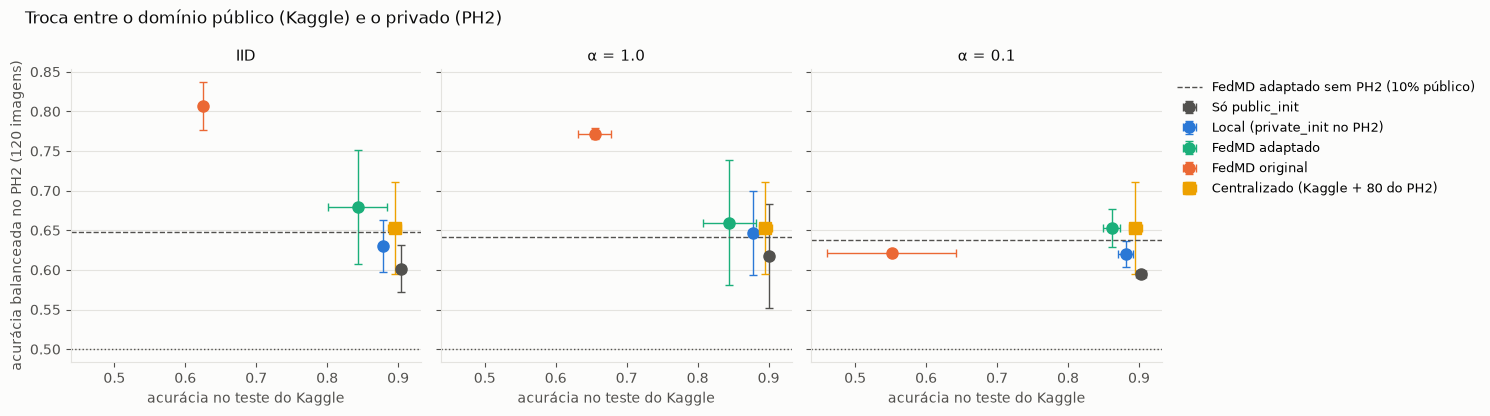

kaggle           ph2_bal         
modelo            clientes ensemble clientes ensemble
alpha método                                         
0.1   Local          0.881    0.881    0.620    0.596
      adaptado       0.862    0.862    0.653    0.662
      original       0.551    0.551    0.621    0.682
      public_init    0.902    0.902    0.594    0.596
1.0   Local          0.878    0.878    0.646    0.589
      adaptado       0.844    0.844    0.660    0.674
      original       0.655    0.655    0.772    0.845
      public_init    0.901    0.901    0.618    0.638
iid   Local          0.879    0.879    0.630    0.651
      adaptado       0.843    0.843    0.679    0.695
      original       0.625    0.625    0.807    0.873
      public_init    0.904    0.904    0.602    0.617

In [12]:
D8 = f'{R}/ph2_privado'
METODOS_8 = {'public_init': ('Só public_init', MUTED), 'Local': ('Local (private_init no PH2)', C[0]),
             'adaptado': ('FedMD adaptado', C[2]), 'original': ('FedMD original', C[1])}
linhas = []
for seed in (42, 1):
    for alpha in ALPHAS:
        for metodo, rounds in (('adaptado', (26, 30)), ('original', (16, 20))):
            base = f'{D8}/{metodo}_seed{seed}_alpha{alpha}'
            t, x = load(f'{base}_test_metrics.csv'), load(f'{base}_extra_test_metrics.csv')
            sel = {metodo: lambda d, r=rounds: d[(d.stage == 'federated') & (d['round'].between(*r))]}
            if metodo == 'adaptado':
                sel = {'public_init': lambda d: d[d.stage == 'public_init'], 'Local': lambda d: d[d.stage == 'private_init'], **sel}
            for nome, f in sel.items():
                for modelo, xx in (('clientes', x[x.model != 'ensemble']), ('ensemble', x[x.model == 'ensemble'])):
                    linhas.append({'seed': seed, 'alpha': alpha, 'método': nome, 'modelo': modelo,
                                   'kaggle': f(t).test_accuracy.mean(), 'ph2_bal': f(xx).balanced_accuracy.mean()})
p8 = pd.DataFrame(linhas)
central8 = pd.read_csv(f'{D8}/centralizado.csv')
central8 = central8[central8.model != 'ensemble']
sem_ph2 = pd.read_csv(f'{D8}/reavaliacao_modelos_salvos.csv')
sem_ph2 = sem_ph2[(sem_ph2['método'] == 'adaptado') & (sem_ph2.public_fraction == 0.1) & (sem_ph2.model != 'ensemble')]
sem_ph2['alpha'] = sem_ph2.alpha.astype(str)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
for ax, alpha in zip(axes, ALPHAS):
    for metodo, (rotulo, cor) in METODOS_8.items():
        g = p8[(p8['método'] == metodo) & (p8.alpha == alpha) & (p8.modelo == 'clientes')]
        ax.errorbar(g.kaggle.mean(), g.ph2_bal.mean(), xerr=g.kaggle.std(), yerr=g.ph2_bal.std(), color=cor,
                    marker='o', ms=8, capsize=3, elinewidth=1, ls='none', label=rotulo)
    ax.errorbar(central8.test_accuracy.mean(), central8.ph2_balanced_accuracy.mean(), xerr=central8.test_accuracy.std(),
                yerr=central8.ph2_balanced_accuracy.std(), color=C[3], marker='s', ms=8, capsize=3, elinewidth=1, ls='none',
                label='Centralizado (Kaggle + 80 do PH2)')
    ax.axhline(sem_ph2[sem_ph2.alpha == alpha].ph2_120_balanced_accuracy.mean(), color=MUTED, ls='--', lw=1,
               label='FedMD adaptado sem PH2 (10% público)')
    ax.axhline(0.5, color=MUTED, ls=':', lw=1)
    ax.set_xlabel('acurácia no teste do Kaggle')
    ax.set_title(ALPHA_LABEL[alpha])
axes[0].set_ylabel('acurácia balanceada no PH2 (120 imagens)')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
fig.suptitle('Troca entre o domínio público (Kaggle) e o privado (PH2)', color=TEXT, x=0.02, ha='left')
fig.tight_layout()
save(fig, '8_ph2_privado_troca')
plt.show()

p8.pivot_table(index=['alpha', 'método'], columns='modelo', values=['kaggle', 'ph2_bal']).round(3)